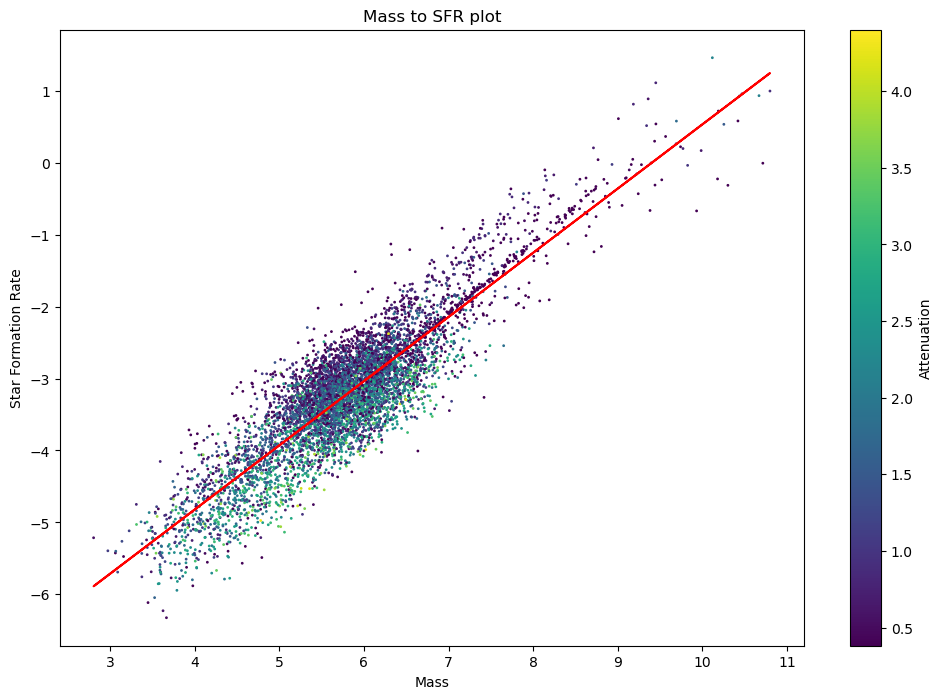

In [ ]:
from astropy.io import fits
from astropy.table import Table
import matplotlib.pyplot as plt
import numpy as np

results = fits.open('results.fits')

table = Table(results[1].data)

mass = table['bayes.stellar.m_star']
sfr = table['bayes.sfh.sfr']
attenuation = table['bayes.attenuation.Av_BC']

log_mass = np.log10(mass)
log_sfr = np.log10(sfr)

a, b = np.polyfit(log_mass, log_sfr, 1)

linear_fit = a*log_mass + b

plt.figure(figsize=(12, 8)) 
scatter = plt.scatter(log_mass, log_sfr, s=1, c=attenuation, cmap='viridis')
cbar = plt.colorbar(scatter)  
cbar.set_label('Attenuation')
plt.plot(log_mass, linear_fit, color = "red")
plt.xlabel('log(Mass)')
plt.ylabel('log(Star Formation Rate)')
plt.title('Mass to SFR log-log plot')
plt.show()